In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt

In [ ]:
iris=load_iris()
x=iris.data[:,:2]
y=(iris.target==0).astype(int)

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Splitted")

Splitted


In [ ]:
model=SVC(kernel="linear",C=1.0)
model.fit(x_train,y_train)

SVC(kernel='linear')

In [ ]:
y_pred=model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy:{accuracy:.4f}")

Accuracy:1.0000


In [ ]:
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=["Setosa","Non-Setosa"]))

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        20
  Non-Setosa       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
w=model.coef_[0]
b=model.intercept_[0]
print("\nWeight vector:",w)
print("Bias:",b)


Weight vector: [-2.44999622  2.45000378]
Bias: 5.409971273612131


In [ ]:
margin=2/np.linalg.norm(w)
print("Margin:",margin)

Margin: 0.577230025457719


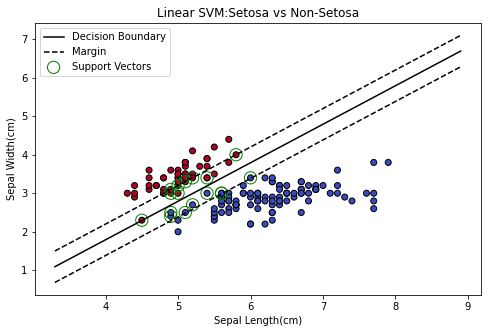

In [39]:
x_min,x_max=x[:,0].min()-1,x[:,0].max()+1
y_min,y_max=x[:,1].min()-1,x[:,1].max()+1
xx,yy=np.meshgrid(np.linspace(x_min,x_max,200),np.linspace(y_min,y_max,200))
#plt.contour(xx,yy,z,alpha=0.2,cmap='coolwarm')
plt.figure(figsize=(8,5))
plt.scatter(x[:,0],x[:,1],c=y,cmap='coolwarm',edgecolors='black')
x_line=np.linspace(x_min,x_max,200)
y_line=-(w[0]*x_line+b)/w[1]
plt.plot(x_line,y_line,'k-',label='Decision Boundary')
plt.plot(x_line,y_line+1/w[1],'k--',label='Margin')
plt.plot(x_line,y_line-1/w[1],'k--')
plt.scatter(model.support_vectors_[:,0],
            model.support_vectors_[:,1],
            s=150,facecolors='none',edgecolors='green',
            label='Support Vectors'
           )
plt.xlabel('Sepal Length(cm)')
plt.ylabel('Sepal Width(cm)')
plt.title('Linear SVM:Setosa vs Non-Setosa')
plt.legend()
plt.show()